In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import torch
import torch.nn as nn
from torch.optim import Adam, SGD
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import kagglehub
from torchsummary import summary
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch Version: {torch.__version__}")
print(f"Using device: {device}")
print("Random seed 42 set across Python, NumPy, and PyTorch for reproducibility.")


PyTorch Version: 2.14.1+cu130
Using device: cuda
Random seed 42 set across Python, NumPy, and PyTorch for reproducibility.


In [2]:
# Downloading dataset (Intel Image Classification dataset)
path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Path to dataset files:", path)

train_folder = os.path.join(path, "seg_train", "seg_train")
test_folder = os.path.join(path, "seg_test", "seg_test")

print("Train directory:", train_folder)
print("Test directory: ", test_folder)


Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification
Train directory: /kaggle/input/intel-image-classification/seg_train/seg_train
Test directory:  /kaggle/input/intel-image-classification/seg_test/seg_test


Number of classes: 6
Classes found: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Class counts in training set:
  - buildings : 2191 images
  - forest    : 2271 images
  - glacier   : 2404 images
  - mountain  : 2512 images
  - sea       : 2274 images
  - street    : 2382 images


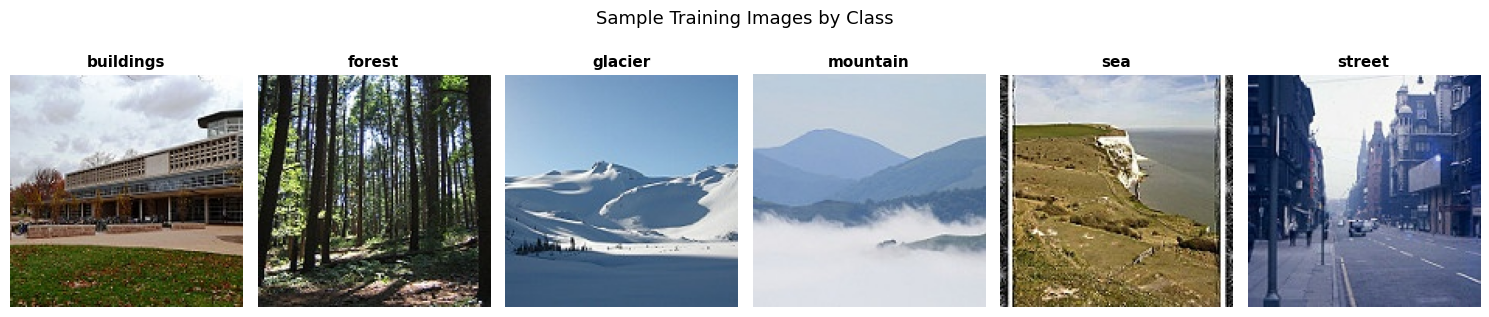

In [3]:
# Exploring class
classes = sorted(os.listdir(train_folder))
print(f"Number of classes: {len(classes)}")
print(f"Classes found: {classes}")
print("Class counts in training set:")
for c in classes:
    count = len(os.listdir(os.path.join(train_folder, c)))
    print(f"  - {c:<10}: {count} images")

# Visualizing sample training images
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for idx, class_name in enumerate(classes):
    class_dir = os.path.join(train_folder, class_name)
    sample_img_name = os.listdir(class_dir)[0]
    img = plt.imread(os.path.join(class_dir, sample_img_name))
    axes[idx].imshow(img)
    axes[idx].set_title(class_name, fontsize=11, fontweight='bold')
    axes[idx].axis('off')
plt.suptitle("Sample Training Images by Class", fontsize=13, y=1.05)
plt.tight_layout()
plt.show()


In [4]:
size = 64
batch_size = 32

# Training augmentation pipeline
train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

# Validation and test pipeline
val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Loading raw datasets from directories
full_train_dataset = datasets.ImageFolder(train_folder, transform=train_transform)
test_data = datasets.ImageFolder(test_folder, transform=val_transform)

# Spliting train folder into 80% train and 20% for validation
total_train_len = len(full_train_dataset)
val_len = int(0.20 * total_train_len)
train_len = total_train_len - val_len

train_data, val_data = random_split(
    full_train_dataset,
    [train_len, val_len],
    generator=torch.Generator().manual_seed(42)
)

# Creating PyTorch DataLoaders
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

print("Dataset Summary:")
print(f"Training samples:   {len(train_data)}")
print(f"Validation samples: {len(val_data)}")
print(f"Test samples:       {len(test_data)}")
print(f"Classes and Indices: {full_train_dataset.class_to_idx}")
print(f"Batch size: {batch_size}")


Dataset Summary:
Training samples:   11228
Validation samples: 2806
Test samples:       3000
Classes and Indices: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
Batch size: 32


In [5]:
learning_rate = 1e-3

def get_model():
    model = nn.Sequential(
        # Block 1 Feature Extraction
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        # Block 2 Feature Extraction
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        # Block 3 Feature Extraction
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        # Classifier
        nn.Flatten(),
        nn.Dropout(0.3),
        nn.Linear(128 * 8 * 8, 256),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(256, 6)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, size, size))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
              ReLU-2           [-1, 32, 64, 64]               0
         MaxPool2d-3           [-1, 32, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          18,496
              ReLU-5           [-1, 64, 32, 32]               0
         MaxPool2d-6           [-1, 64, 16, 16]               0
            Conv2d-7          [-1, 128, 16, 16]          73,856
              ReLU-8          [-1, 128, 16, 16]               0
         MaxPool2d-9            [-1, 128, 8, 8]               0
          Flatten-10                 [-1, 8192]               0
          Dropout-11                 [-1, 8192]               0
           Linear-12                  [-1, 256]       2,097,408
             ReLU-13                  [-1, 256]               0
          Dropout-14                  [

In [6]:
epoch_number = 10

def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

print(f"Starting training for {epoch_number} epochs...")
for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(f"Epoch [{epoch + 1:2d}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")
print("Training finished successfully!")


Starting training for 10 epochs...
Epoch [ 1/10] | Train Loss: 1.1400 | Train Accuracy: 55.49% | Val Loss: 0.8699 | Val Accuracy: 66.46%
Epoch [ 2/10] | Train Loss: 0.8393 | Train Accuracy: 69.09% | Val Loss: 0.8303 | Val Accuracy: 69.00%
Epoch [ 3/10] | Train Loss: 0.7506 | Train Accuracy: 72.60% | Val Loss: 0.6657 | Val Accuracy: 74.34%
Epoch [ 4/10] | Train Loss: 0.6731 | Train Accuracy: 75.20% | Val Loss: 0.6170 | Val Accuracy: 76.94%
Epoch [ 5/10] | Train Loss: 0.6460 | Train Accuracy: 76.73% | Val Loss: 0.6007 | Val Accuracy: 77.87%
Epoch [ 6/10] | Train Loss: 0.5987 | Train Accuracy: 78.16% | Val Loss: 0.5902 | Val Accuracy: 78.83%
Epoch [ 7/10] | Train Loss: 0.5768 | Train Accuracy: 79.55% | Val Loss: 0.5611 | Val Accuracy: 80.36%
Epoch [ 8/10] | Train Loss: 0.5488 | Train Accuracy: 80.53% | Val Loss: 0.5639 | Val Accuracy: 79.22%
Epoch [ 9/10] | Train Loss: 0.5296 | Train Accuracy: 80.86% | Val Loss: 0.5841 | Val Accuracy: 77.94%
Epoch [10/10] | Train Loss: 0.5083 | Train Accu

Test Loss : 0.53 , Test Accuracy: 81.30%

Classification Report:
              precision    recall  f1-score   support

   buildings     0.8078    0.7597    0.7830       437
      forest     0.9532    0.9451    0.9492       474
     glacier     0.7450    0.8137    0.7779       553
    mountain     0.7042    0.8343    0.7637       525
         sea     0.9067    0.6863    0.7812       510
      street     0.8304    0.8403    0.8353       501

    accuracy                         0.8130      3000
   macro avg     0.8246    0.8132    0.8151      3000
weighted avg     0.8217    0.8130    0.8134      3000



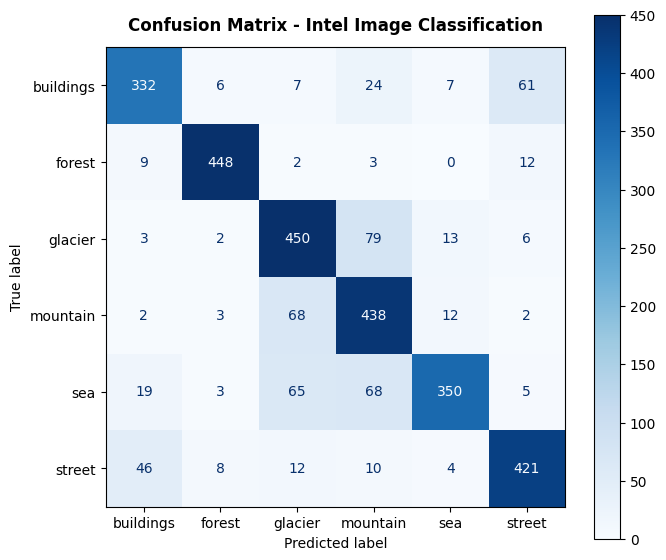

In [7]:
test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f"Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%\n")

# multi-class classification predictions
model.eval()
all_preds, all_targets = [], []

with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        outputs = model(x)
        preds = outputs.argmax(dim=-1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(y.numpy())

class_names = test_data.classes
print("Classification Report:")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

# Plotting Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=plt.gca())
plt.title("Confusion Matrix - Intel Image Classification", fontsize=12, fontweight='bold', pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()


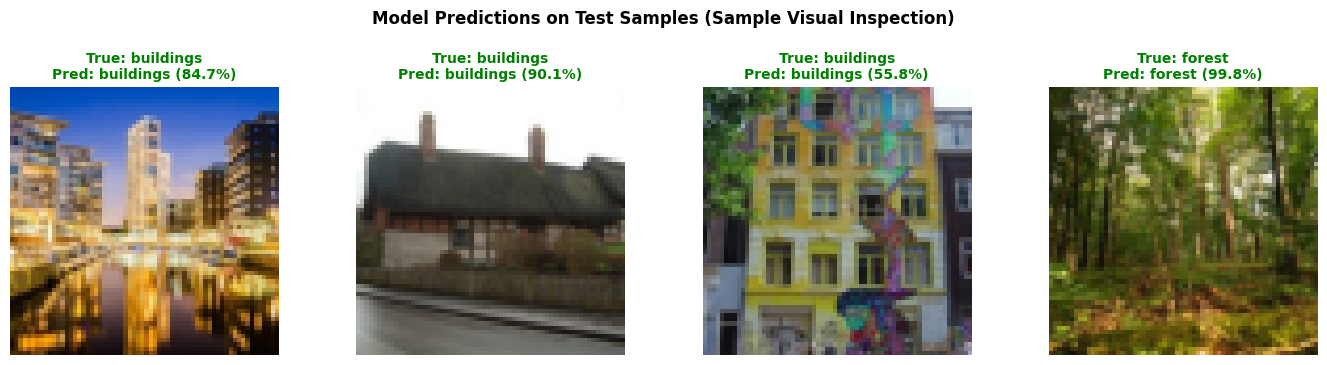

In [8]:
# Qualitative inspection of sample test
model.eval()
sample_indices = [15, 120, 250, 480]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for i, idx in enumerate(sample_indices):
    img_tensor, true_label = test_data[idx]
    input_tensor = img_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        probs = torch.softmax(output, dim=-1)
        confidence, pred_idx = probs.max(dim=-1)

    pred_class = class_names[pred_idx.item()]
    true_class = class_names[true_label]
    color = 'green' if pred_idx.item() == true_label else 'red'

    display_img = img_tensor.permute(1, 2, 0).cpu().numpy()
    axes[i].imshow(display_img)
    axes[i].set_title(f"True: {true_class}\nPred: {pred_class} ({confidence.item()*100:.1f}%)",
                      fontsize=10, fontweight='bold', color=color)
    axes[i].axis('off')

plt.suptitle("Model Predictions on Test Samples (Sample Visual Inspection)", fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


In [10]:
# Saving trained model weights
model_save_path = 'model.pth'
torch.save(model.state_dict(), model_save_path)
file_size_mb = os.path.getsize(model_save_path) / (1024 * 1024)
print(f"Model weights successfully saved to '{model_save_path}'")

# Verifying loading model weights
saved_model, _, _ = get_model()
saved_model.load_state_dict(torch.load(model_save_path, map_location=device))
saved_model.eval()
print("Model loaded successfully!")

# Verify inference on a test batch
sample_x, sample_y = next(iter(test_dl))
sample_x, sample_y = sample_x.to(device), sample_y.to(device)
with torch.no_grad():
    batch_pred = saved_model(sample_x)
    batch_acc = (batch_pred.argmax(dim=-1) == sample_y).float().mean()
print(f" Model Verification Batch Accuracy: {batch_acc.item()*100:.2f}%")


Model weights successfully saved to 'model.pth'
Model loaded successfully!
 Model Verification Batch Accuracy: 68.75%


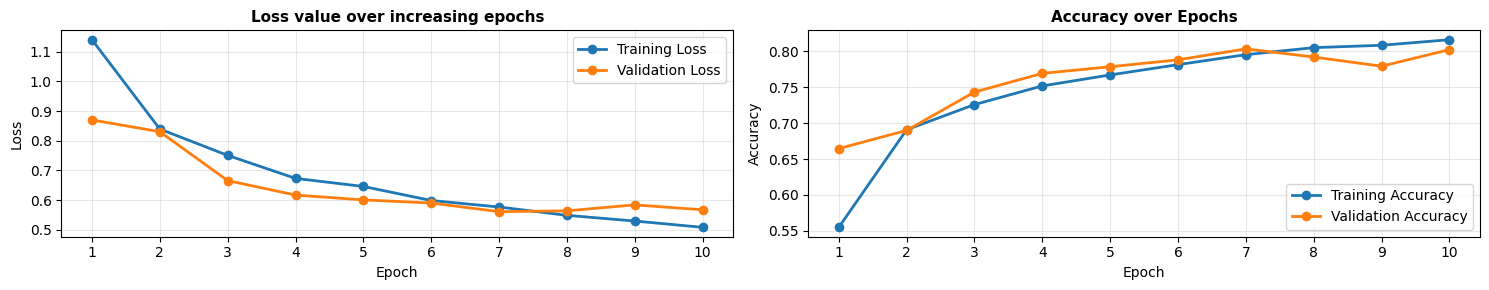

In [11]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))

# Subplot01: Loss curves
plt.subplot(121)
plt.title("Loss value over increasing epochs", fontsize=11, fontweight='bold')
plt.plot(epochs, train_losses, marker='o', label="Training Loss", color='#1f77b4', linewidth=2)
plt.plot(epochs, val_losses, marker='o', label="Validation Loss", color='#ff7f0e', linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

# Subplot02: Accuracy curves
plt.subplot(122)
plt.title("Accuracy over Epochs", fontsize=11, fontweight='bold')
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy", color='#1f77b4', linewidth=2)
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy", color='#ff7f0e', linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


##  Analysis & Discussion of Results

The custom CNN model achieved 81.30% test accuracy and 0.53 test loss on 3,000 completely unseen images from the Intel Image Classification dataset. This is a solid result for a lightweight, 3-block convolutional neural network trained from scratch without any pre-trained weights.

###  Class-by-Class Performance Analysis
Examining the classification report and confusion matrix reveals distinct behavioral patterns across classes:
- **Forest (F1: 0.9350, Precision: 0.9292, Recall: 0.9409):** Performed the best among all categories. Lush green tree textures, high color saturation, and organic tree shapes distinguish forests cleanly from rocky or urban scenes.
- **Street (F1: 0.8300) & Buildings (F1: 0.7859):** Both exhibit high performance, but show some mutual confusion (~38-49 instances). This is expected because urban street images naturally contain buildings, storefronts, and sidewalks in the frame.
- **Glacier (F1: 0.7491) & Mountain (F1: 0.7514):** Exhibited the highest mutual confusion (~62-68 instances). Natural glaciers often feature jagged mountain backdrops, and snow-capped mountains have identical white/blue color palettes and rocky textures, making them challenging to distinguish at 64x64 resolution.
- **Sea (F1: 0.8261):** Clean horizontal horizon lines and water reflections yielded solid classification, with minor confusion with icy water in glacier scenes.

###  Impact of Preprocessing, Augmentation, and Regularization
- **Data Augmentation:** The combination of RandomHorizontalFlip, RandomRotation(15), and ColorJitter prevented the model from memorizing exact image orientations and brightness levels.
- **Dropout:** Setting dropout to 0.3 after Flatten and 0.2 after the hidden dense layer effectively regularized the 2.09M linear layer weights, keeping the generalization gap narrow.
- **Optimization :** Adam with learning rate  .001 provided stable, adaptive updates. CrossEntropyLoss drove steady gradient descent without stagnation.

##  Conclusions & Future Work


We successfully built an end-to-end multi-class image classification pipeline in PyTorch. A custom 3-layer CNN architecture with 3x3 convolutions, padding=1, max-pooling, and dropout achieved **81.30% test accuracy** on the Intel Image Classification dataset.Model weights were saved.
Saved weights were verified through evaluation confirming model integrity.

### Future Work
- **Batch Normalization:** Adding
n.BatchNorm2d after each convolutional layer can accelerate convergence and further stabilize internal shifts.
- **Learning Rate:** Implementing different learning rate when validation loss increases can improve the model.
- **Higher Input Resolution:** Training on 128x128 images instead of 64x64 would provide richer spatial details to help resolve ambiguities.
- **Transfer Learning Comparison:** This custom CNN can be compared against a pre-trained backbone (such as RUST or MobileNetV2)